# Redução de dimensionalidade e clusterização

Três técnicas, todas feitas **só com o desenvolvimento** (80%); o teste não é aberto.

| Seção | Técnica | O que o PDF diz |
|---|---|---|
| 1 | **PCA exploratório** | Entender quantas dimensões realmente importam |
| 2 | **PCA dentro do `Pipeline`** | **Obrigatório:** testar em pelo menos 2 regressores, justificar o número de componentes e comparar com os modelos sem PCA |
| 3 | **t-SNE** | **Opcional:** só numa amostra, como diagnóstico; não substitui a base |
| 4 | **K-means** | Não é exigido; se usado, tem de ficar **dentro do `Pipeline`** (aprendido só no treino de cada dobra) |

**O que cada uma faz, em uma frase:**
- **PCA** troca as 30 colunas por novas colunas (componentes), não correlacionadas entre si e ordenadas pela quantidade de variação que carregam. Dá para ficar só com as primeiras.
- **t-SNE** desenha as pessoas em 2 dimensões de forma que as parecidas fiquem perto. Serve só para olhar.
- **K-means** agrupa as pessoas parecidas em `k` grupos.

**Tempo estimado:** de 25 a 35 minutos (a seção 2 treina o Gradient Boosting 6 vezes).

## 0. Preparação

Igual aos outros notebooks: lê o dataset, fica só com o desenvolvimento e carrega as dobras salvas. Para outro dataset, troque a linha `NOME`.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import PredefinedSplit, cross_val_predict, cross_validate

DATASETS = ["dataset_1_fundido", "dataset_1_features", "dataset_2_escola", "dataset_2_features_escola",
            "dataset_3_sem_escola", "dataset_3_sem_escola_features", "dataset_3_escola", "dataset_3_escola_features"]
NOME = "dataset_1_fundido"        # para treinar em outro dataset, troque só esta linha

# quem está no desenvolvimento (80%) e a dobra (1, 2 ou 3) de cada pessoa: arquivos salvos em dados/splits/
ids = pd.read_csv("../dados/processed/ids_elegiveis.csv")["NU_INSCRICAO"]
em_desenvolvimento = ids.isin(pd.read_csv("../dados/splits/desenvolvimento_ids.csv")["NU_INSCRICAO"]).to_numpy()
dobras = PredefinedSplit(pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy())


def carregar(nome):
    """Lê o dataset e devolve só o desenvolvimento: X (features) e y (nota de Matemática). O teste não é carregado."""
    dev = pd.read_csv(f"../dados/processed/{nome}.csv")[em_desenvolvimento]
    return dev.drop(columns="NU_NOTA_MT"), dev["NU_NOTA_MT"]


X, y = carregar(NOME)
amostra = np.random.default_rng(42).choice(len(y), 20_000, replace=False)   # 20 mil pessoas sorteadas, só para desenhar gráficos
resultados = {}                                                             # aqui ficam as métricas de cada modelo, para a comparação final
print(f"{NOME}: {X.shape[0]:,} pessoas no desenvolvimento, {X.shape[1]} features")

dataset_1_fundido: 2,153,941 pessoas no desenvolvimento, 30 features


A função `avaliar` mede um modelo: ele treina em 2 dobras, é testado na terceira, três vezes, e ela devolve a **média** e o **desvio** de cada métrica. Se você passar um nome, o resultado também vai para `resultados`.

- **RMSE:** o erro típico em pontos de nota (pune mais os erros grandes). É a métrica principal.
- **MAE:** o erro médio em pontos, sem sinal.
- **R²:** quanto da variação da nota o modelo explica (0 = nada além da média, 1 = tudo).
- **MSE:** o erro ao quadrado médio; o RMSE é a raiz dele.
- **tempo_s:** segundos para treinar e prever em uma dobra.

In [2]:
def avaliar(modelo, nome=None):
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error",
                "R2": "r2", "MSE": "neg_mean_squared_error"}      # o scikit-learn devolve os erros com sinal negativo
    r = cross_validate(modelo, X, y, cv=dobras, scoring=metricas)
    por_dobra = pd.DataFrame({"RMSE": -r["test_RMSE"], "MAE": -r["test_MAE"], "R2": r["test_R2"], "MSE": -r["test_MSE"],
                              "tempo_s": r["fit_time"] + r["score_time"]})
    resumo = pd.DataFrame({"média": por_dobra.mean(), "desvio": por_dobra.std()})
    if nome:
        resultados[nome] = resumo
    return resumo.round(3)

## 1. PCA exploratório

Padronizamos as colunas (média 0, desvio 1: o PCA é sensível à escala, e sem isso `Q005` de 1 a 20 pesaria mais que as colunas 0/1) e rodamos o PCA nos 80% do desenvolvimento. **Atenção:** isto é só para olhar os dados. O PCA que entra nos modelos é o da seção 2, reajustado dentro de cada dobra.

50% da variância: 7 componentes (de 30)
80% da variância: 18 componentes (de 30)
90% da variância: 23 componentes (de 30)
95% da variância: 26 componentes (de 30)


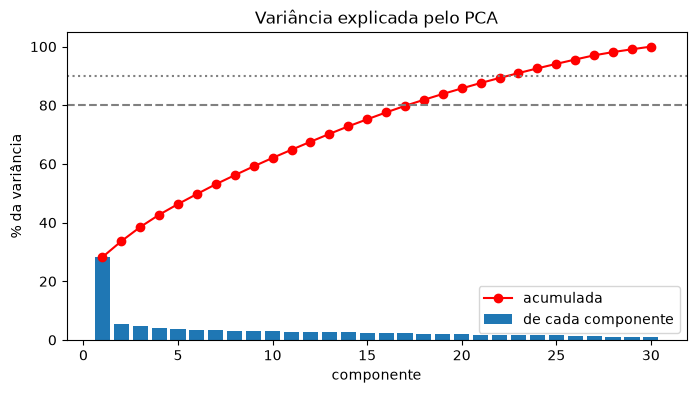

In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

padronizado = StandardScaler().fit_transform(X)            # só exploração: usa todo o desenvolvimento, nunca o teste
pca = PCA(random_state=42).fit(padronizado)
acumulada = np.cumsum(pca.explained_variance_ratio_)

for alvo in (0.5, 0.8, 0.9, 0.95):
    print(f"{alvo * 100:.0f}% da variância: {int(np.argmax(acumulada >= alvo)) + 1} componentes (de {X.shape[1]})")

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(acumulada) + 1), pca.explained_variance_ratio_ * 100, label="de cada componente")
plt.plot(range(1, len(acumulada) + 1), acumulada * 100, color="red", marker="o", label="acumulada")
plt.axhline(80, color="gray", ls="--")
plt.axhline(90, color="gray", ls=":")
plt.xlabel("componente")
plt.ylabel("% da variância")
plt.title("Variância explicada pelo PCA")
plt.legend()
plt.show()

**Como ler:** se poucos componentes juntarem quase toda a variância, os dados "cabem" em poucas dimensões e o PCA ajuda. Se for preciso quase todos, as colunas carregam informações **independentes** e o PCA comprime pouco. É o que se espera aqui, já que nenhum par de features passou de 0,7 de Spearman.

### O que cada componente significa

As **cargas** mostram quanto cada feature pesa no componente (positivo e negativo se opõem). Abaixo, as 10 maiores de cada um dos 3 primeiros, e a correlação de cada componente com a nota.

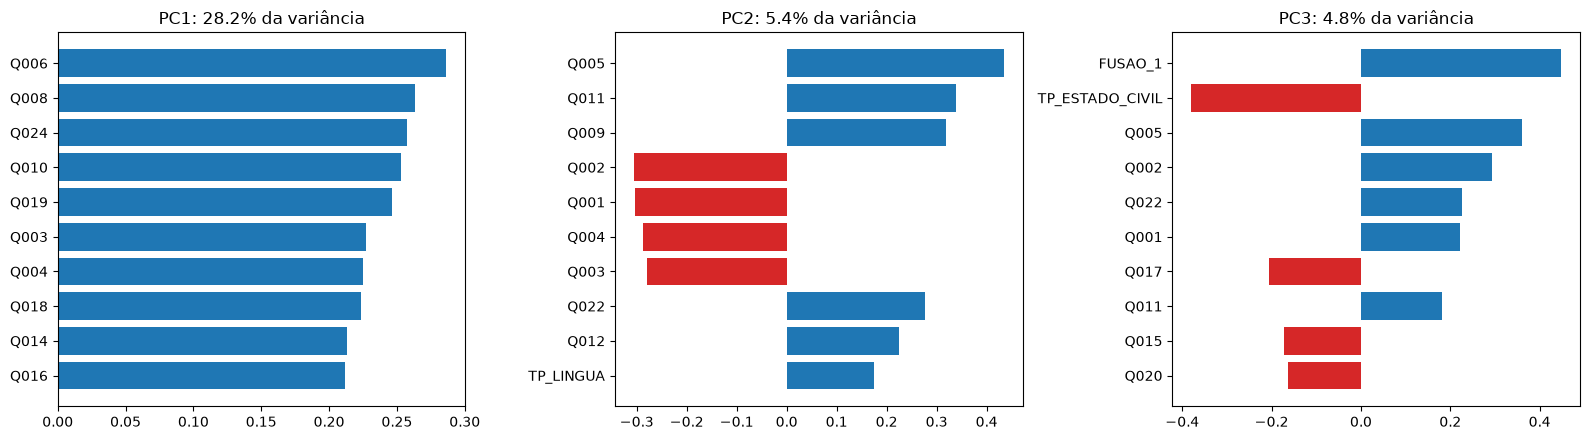

Correlação de cada componente com a nota:
PC1     0.463
PC2    -0.152
PC3    -0.010
PC4     0.066
PC5     0.052
PC6    -0.095
PC7     0.070
PC8    -0.047
PC9    -0.011
PC10   -0.043


In [4]:
cargas = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for i, pc in enumerate(cargas):
    top = cargas[pc].reindex(cargas[pc].abs().sort_values().index).tail(10)
    ax[i].barh(top.index, top.values, color=["tab:red" if v < 0 else "tab:blue" for v in top.values])
    ax[i].set_title(f"{pc}: {pca.explained_variance_ratio_[i] * 100:.1f}% da variância")
plt.tight_layout()
plt.show()

pontos = pca.transform(padronizado)
corr = pd.Series([np.corrcoef(pontos[:, i], y)[0, 1] for i in range(10)], index=[f"PC{i + 1}" for i in range(10)])
print("Correlação de cada componente com a nota:")
print(corr.round(3).to_string())

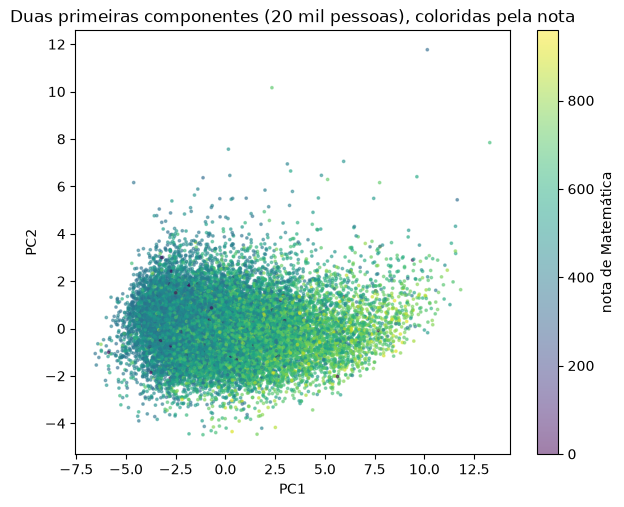

In [5]:
amostra = np.random.default_rng(42).choice(len(y), 20_000, replace=False)
plt.figure(figsize=(7, 5.5))
pontos_amostra = plt.scatter(pontos[amostra, 0], pontos[amostra, 1], c=y.iloc[amostra], cmap="viridis", s=3, alpha=0.5)
plt.colorbar(pontos_amostra, label="nota de Matemática")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Duas primeiras componentes (20 mil pessoas), coloridas pela nota")
plt.show()

## 2. PCA dentro do `Pipeline` (exigência do PDF)

O PDF pede testar o PCA em **pelo menos 2 regressores**, justificar o número de componentes e comparar com os modelos sem PCA, nas mesmas dobras. Testamos dois regressores bem diferentes:

- **Regressão linear:** o PCA aqui só gira as colunas, então o resultado com todos os componentes deve ser igual ao sem PCA; mostra o que se perde ao cortar.
- **Gradient Boosting:** o melhor modelo até agora. Árvores costumam não precisar de PCA, então é o teste mais exigente.

A receita é `StandardScaler → PCA(k componentes) → regressor`. Dentro da validação cruzada, **a padronização e o PCA são reajustados só no treino de cada dobra**. Testamos `k` = 5, 10, 15, 20 e 25 (de 30) e o "sem PCA".

**Como justificar o `k`:** o menor `k` cujo RMSE fica **dentro de 1 desvio** do RMSE sem PCA, isto é, quando cortar componentes não faz diferença mensurável. Estimativa de tempo: cerca de 12 minutos (o Gradient Boosting é treinado 6 vezes).

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

regressores = {"Regressão linear": LinearRegression(),
               "Gradient Boosting": HistGradientBoostingRegressor(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
                                                                  early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42)}
ks = [k for k in (5, 10, 15, 20, 25) if k < X.shape[1]]

linhas = []
for nome, regressor in regressores.items():
    r = avaliar(make_pipeline(StandardScaler(), regressor))
    linhas.append({"modelo": nome, "componentes": "sem PCA", "RMSE": r.loc["RMSE", "média"], "desvio": r.loc["RMSE", "desvio"],
                   "R2": r.loc["R2", "média"], "tempo_s": r.loc["tempo_s", "média"]})
    for k in ks:
        r = avaliar(make_pipeline(StandardScaler(), PCA(n_components=k, random_state=42), regressor))
        linhas.append({"modelo": nome, "componentes": k, "RMSE": r.loc["RMSE", "média"], "desvio": r.loc["RMSE", "desvio"],
                       "R2": r.loc["R2", "média"], "tempo_s": r.loc["tempo_s", "média"]})
    print(f"{nome}: ok")
tabela_pca = pd.DataFrame(linhas)
tabela_pca.round(3)

Regressão linear: ok
Gradient Boosting: ok


,modelo,componentes,RMSE,desvio,R2,tempo_s
0,Regressão linear,sem PCA,111.153,0.178,0.287,1.226
1,Regressão linear,5,114.425,0.174,0.244,0.836
2,Regressão linear,10,113.047,0.190,0.262,0.844
3,Regressão linear,15,112.718,0.184,0.267,0.905
4,Regressão linear,20,111.887,0.177,0.278,1.150
5,Regressão linear,25,111.658,0.181,0.280,1.638
6,Gradient Boosting,sem PCA,107.770,0.226,0.330,89.468
7,Gradient Boosting,5,113.210,0.168,0.260,42.924
8,Gradient Boosting,10,111.551,0.152,0.282,86.210
9,Gradient Boosting,15,111.148,0.181,0.287,64.410


### Gráfico e escolha do número de componentes

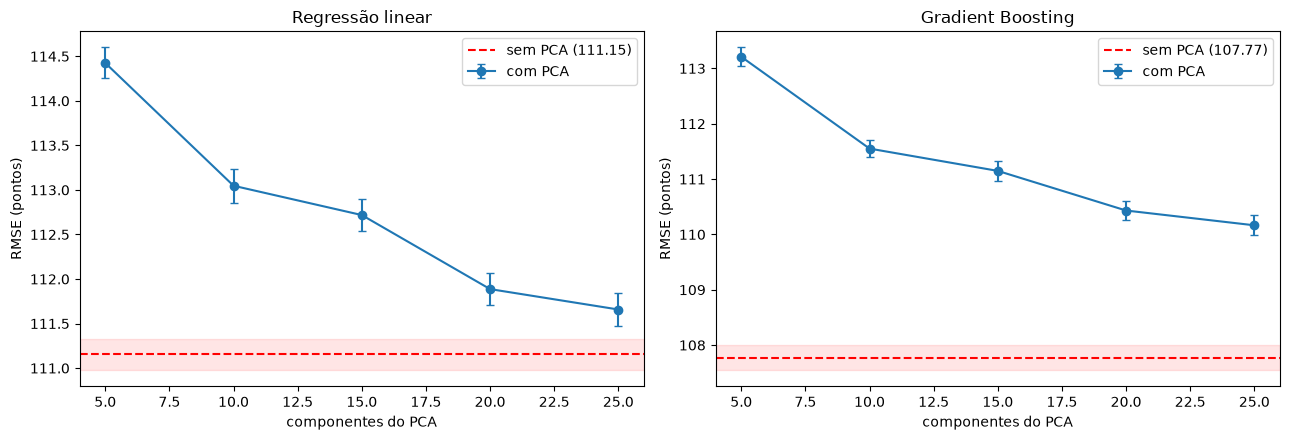

Menor número de componentes cujo RMSE fica dentro de 1 desvio do modelo sem PCA:
   Regressão linear     nenhum dos k testados (sem PCA é melhor: 111.15)
   Gradient Boosting    nenhum dos k testados (sem PCA é melhor: 107.77)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i, nome in enumerate(regressores):
    t = tabela_pca[tabela_pca["modelo"] == nome]
    sem = t[t["componentes"] == "sem PCA"].iloc[0]
    com = t[t["componentes"] != "sem PCA"]
    ax[i].errorbar(com["componentes"].astype(int), com["RMSE"], yerr=com["desvio"], marker="o", capsize=3, label="com PCA")
    ax[i].axhline(sem["RMSE"], color="red", ls="--", label=f"sem PCA ({sem['RMSE']:.2f})")
    ax[i].axhspan(sem["RMSE"] - sem["desvio"], sem["RMSE"] + sem["desvio"], color="red", alpha=0.1)
    ax[i].set_title(nome)
    ax[i].set_xlabel("componentes do PCA")
    ax[i].set_ylabel("RMSE (pontos)")
    ax[i].legend()
plt.tight_layout()
plt.show()

print("Menor número de componentes cujo RMSE fica dentro de 1 desvio do modelo sem PCA:")
for nome in regressores:
    t = tabela_pca[tabela_pca["modelo"] == nome]
    sem = t[t["componentes"] == "sem PCA"].iloc[0]
    com = t[(t["componentes"] != "sem PCA") & (t["RMSE"] <= sem["RMSE"] + sem["desvio"])]
    print(f"   {nome:<20} " + (f"k = {int(com['componentes'].min())}" if len(com) else f"nenhum dos k testados (sem PCA é melhor: {sem['RMSE']:.2f})"))

**Como ler:** a linha vermelha é o modelo sem PCA e a faixa clara é o desvio entre as dobras. Se a curva com PCA não chega à faixa, cortar componentes **perde informação**. Se chegar só com quase todos os componentes, o PCA não comprime. Os dois resultados são válidos para o artigo: o PDF diz que ganhos pequenos e ausência de melhoria devem ser discutidos.

## 3. t-SNE (diagnóstico, opcional)

O t-SNE desenha as pessoas em 2 dimensões, mantendo perto as que são parecidas. **Só serve para olhar:** ele não aprende uma regra que se aplique a pessoas novas, então **não entra em nenhum modelo**. Como é caro, usamos **15 mil pessoas sorteadas** do desenvolvimento; o PDF aceita isso porque é só diagnóstico e não substitui a base. Cada ponto é pintado pela nota, e depois pela renda (`Q006`). Estimativa: de 1 a 3 minutos.

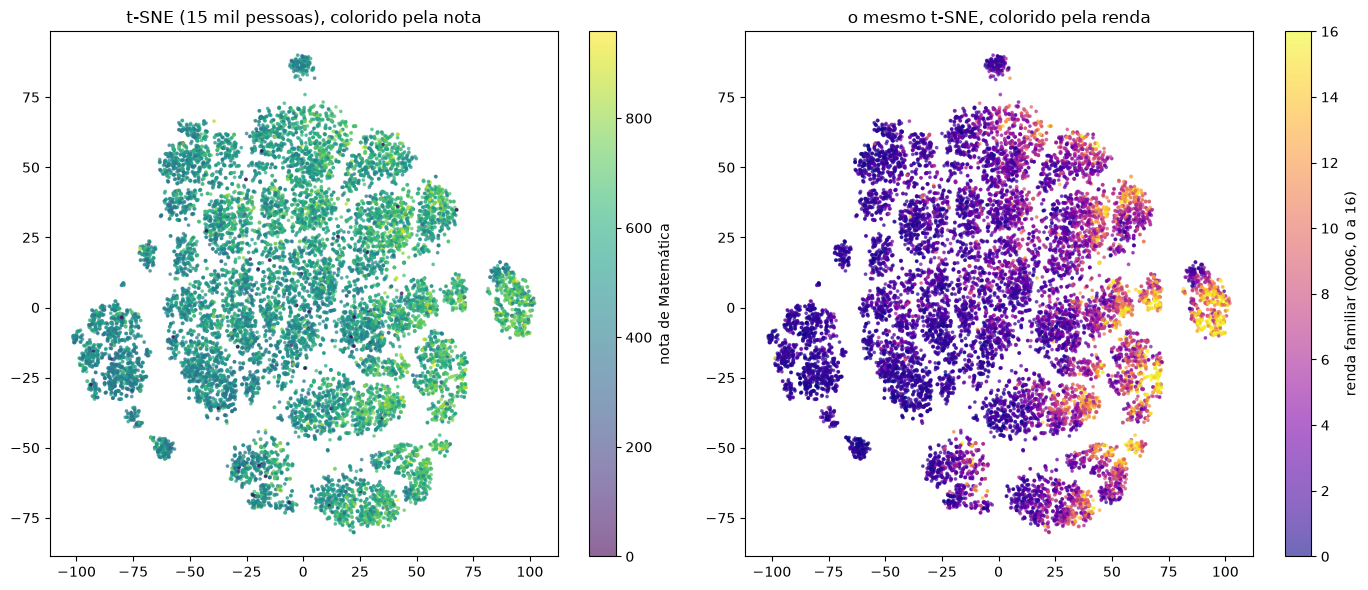

In [8]:
from sklearn.manifold import TSNE

sub = np.random.default_rng(42).choice(len(X), 15_000, replace=False)
Z = StandardScaler().fit_transform(X.iloc[sub])
embedding = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(Z)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
a = ax[0].scatter(embedding[:, 0], embedding[:, 1], c=y.iloc[sub], cmap="viridis", s=3, alpha=0.6)
fig.colorbar(a, ax=ax[0], label="nota de Matemática")
ax[0].set_title("t-SNE (15 mil pessoas), colorido pela nota")
b = ax[1].scatter(embedding[:, 0], embedding[:, 1], c=X["Q006"].iloc[sub], cmap="plasma", s=3, alpha=0.6)
fig.colorbar(b, ax=ax[1], label="renda familiar (Q006, 0 a 16)")
ax[1].set_title("o mesmo t-SNE, colorido pela renda")
plt.tight_layout()
plt.show()

**Como ler:** se as cores formarem **manchas e gradientes** (regiões de nota alta separadas de regiões de nota baixa), as features organizam as pessoas de um jeito ligado à nota. Se estiver tudo **misturado**, as features não separam bem as notas, o que combina com um R² baixo. Distâncias grandes entre grupos no t-SNE não devem ser interpretadas ao pé da letra: ele preserva vizinhanças, não distâncias.

## 4. K-means

Agrupa as pessoas parecidas em `k` grupos. Duas perguntas: (1) **existem perfis naturais** de participantes? (2) **dar o grupo ao modelo** ajuda a prever a nota?

### Parte 1: quantos grupos? (exploratório)

Rodamos o `MiniBatchKMeans` (versão rápida do K-means, própria para milhões de linhas) para `k` de 2 a 10 nos 80% padronizados. Dois indicadores: a **inércia** (quão apertados estão os grupos; sempre cai com mais grupos, então procuramos o "cotovelo") e a **silhueta** (de −1 a 1; quanto maior, mais bem separados os grupos, medida em 10 mil pessoas sorteadas).

         inércia  silhueta
k                         
2   5.239538e+07     0.207
3   4.862089e+07     0.104
4   4.678045e+07     0.073
5   4.638478e+07     0.084
6   4.496412e+07     0.052
7   4.387206e+07     0.068
8   4.260722e+07     0.048
9   4.184398e+07     0.049
10  4.124554e+07     0.048


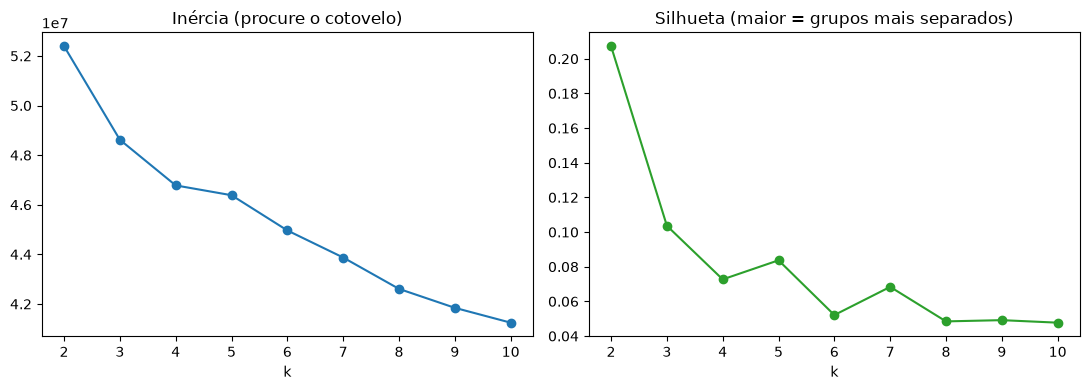

In [9]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

pequena = np.random.default_rng(42).choice(len(X), 10_000, replace=False)
linhas = []
for k in range(2, 11):
    km = MiniBatchKMeans(n_clusters=k, n_init=3, batch_size=10_000, random_state=42).fit(padronizado)
    linhas.append({"k": k, "inércia": km.inertia_, "silhueta": silhouette_score(padronizado[pequena], km.labels_[pequena])})
escolha_k = pd.DataFrame(linhas).set_index("k")
print(escolha_k.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(escolha_k.index, escolha_k["inércia"], marker="o")
ax[0].set_title("Inércia (procure o cotovelo)")
ax[0].set_xlabel("k")
ax[1].plot(escolha_k.index, escolha_k["silhueta"], marker="o", color="tab:green")
ax[1].set_title("Silhueta (maior = grupos mais separados)")
ax[1].set_xlabel("k")
plt.tight_layout()
plt.show()

Em dados de perfil, os grupos costumam ser **pouco separados** (silhueta baixa, abaixo de 0,25): as pessoas formam um contínuo, não ilhas. Usamos o `k` de maior silhueta e descrevemos os grupos.

In [10]:
K = int(escolha_k["silhueta"].idxmax())
kmeans = MiniBatchKMeans(n_clusters=K, n_init=3, batch_size=10_000, random_state=42).fit(padronizado)
grupo = pd.Series(kmeans.labels_, index=X.index, name="grupo")

perfil = X[["Q006", "Q001", "Q002", "Q024", "Q025", "TP_SEXO", "TP_LINGUA"]].groupby(grupo).mean()
perfil.insert(0, "pessoas", grupo.value_counts().sort_index())
perfil["nota média"] = y.groupby(grupo).mean()
perfil["nota desvio"] = y.groupby(grupo).std()
print(f"k escolhido: {K}")
perfil.round(2)

k escolhido: 2


,pessoas,Q006,Q001,Q002,Q024,Q025,TP_SEXO,TP_LINGUA,nota média,nota desvio
grupo,,,,,,,,,,
0,1448442,2.03,2.77,3.18,0.36,0.88,0.64,0.53,497.95,115.87
1,705499,7.62,4.39,4.74,1.58,1.00,0.55,0.20,607.50,131.41


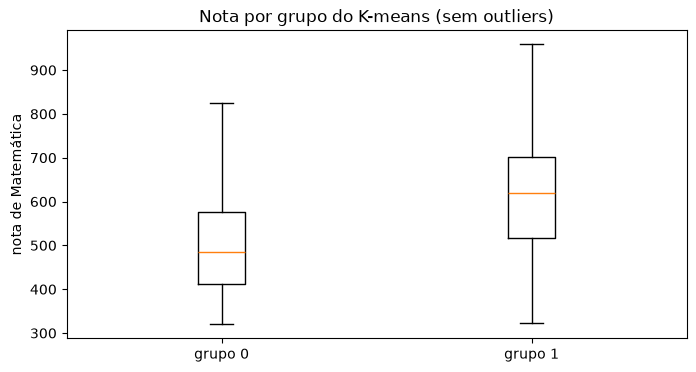

In [11]:
plt.figure(figsize=(8, 4))
plt.boxplot([y[grupo == g] for g in range(K)], tick_labels=[f"grupo {g}" for g in range(K)], showfliers=False)
plt.ylabel("nota de Matemática")
plt.title("Nota por grupo do K-means (sem outliers)")
plt.show()

**Como ler:** se as notas médias dos grupos forem **bem diferentes** (e as caixas quase não se sobrepuserem), os grupos capturam algo ligado à nota. Se as caixas se sobrepõem muito, os grupos são só "rótulos de perfil" e a nota varia muito dentro de cada um.

### Parte 2: o grupo ajuda o modelo? (dentro do `Pipeline`)

Para dar o grupo ao modelo, o `Pipeline` acrescenta às 30 colunas as **distâncias da pessoa até o centro de cada grupo** (o `transform` do K-means). O K-means é **reajustado só no treino de cada dobra**, como o PDF exige. Comparamos o Gradient Boosting com e sem essas colunas, nas mesmas dobras. Estimativa: cerca de 5 minutos.

In [12]:
from sklearn.pipeline import make_union

gb = HistGradientBoostingRegressor(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
                                   early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42)
sem_kmeans = make_pipeline(StandardScaler(), gb)
com_kmeans = make_pipeline(StandardScaler(),
                           make_union("passthrough", MiniBatchKMeans(n_clusters=K, n_init=3, batch_size=10_000, random_state=42)),
                           gb)

r_sem = avaliar(sem_kmeans)
r_com = avaliar(com_kmeans)
tabela_kmeans = pd.DataFrame({"Gradient Boosting": r_sem["média"], f"Gradient Boosting + distâncias aos {K} grupos": r_com["média"]}).T
tabela_kmeans["RMSE_desvio"] = [r_sem.loc["RMSE", "desvio"], r_com.loc["RMSE", "desvio"]]
print(f"Diferença de RMSE (sem − com K-means): {r_sem.loc['RMSE', 'média'] - r_com.loc['RMSE', 'média']:+.3f}  (desvio entre dobras ~{r_sem.loc['RMSE', 'desvio']:.3f})")
tabela_kmeans.round(3)

Diferença de RMSE (sem − com K-means): -0.019  (desvio entre dobras ~0.226)


,RMSE,MAE,R2,MSE,tempo_s,RMSE_desvio
Gradient Boosting,107.770,83.825,0.330,11614.509,70.927,0.226
Gradient Boosting + distâncias aos 2 grupos,107.789,83.845,0.329,11618.502,73.075,0.232


**Como ler:** só vale dizer que o K-means ajudou se a diferença passar o desvio entre as dobras. Com um modelo de árvores que já acha interações sozinho, o esperado é **pouca ou nenhuma melhora**; o resultado, qualquer que seja, é registrável.

## 5. O que levar adiante

Anote aqui as decisões, com os números que saíram acima:

- **Quantos componentes** o PCA precisou para 80% e 90% da variância (seção 1) e o `k` justificado na seção 2, para cada regressor.
- **O PCA melhorou ou piorou** os dois regressores em relação aos modelos sem PCA?
- **O que o t-SNE mostrou:** as cores se separam ou se misturam?
- **O K-means:** existem grupos naturais (silhueta) e o modelo melhora com eles?

Para o artigo, qualquer um desses resultados serve, inclusive "o PCA não ajudou porque as features já não eram redundantes": o PDF pede que ganhos pequenos e ausência de melhoria sejam discutidos.